# Homework 2 — Machine Learning for Regression

ML Zoomcamp 2026. Predict `fuel_efficiency_mpg` with linear regression implemented from scratch in NumPy (as in the lectures).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df_full = pd.read_csv('car_fuel_efficiency_2026.csv')
cols = ['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year', 'fuel_efficiency_mpg']
df = df_full[cols]
df.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0


## EDA — does `fuel_efficiency_mpg` have a long tail?

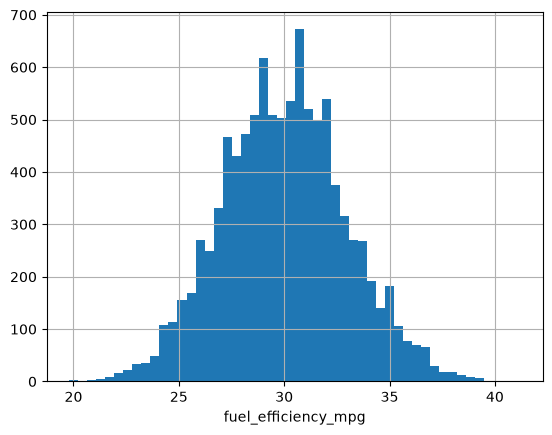

(count    10000.000000
 mean        29.997700
 std          2.930245
 min         19.800000
 25%         28.000000
 50%         30.000000
 75%         31.900000
 max         41.200000
 Name: fuel_efficiency_mpg, dtype: float64,
 np.float64(0.08080419601878173))

In [3]:
df.fuel_efficiency_mpg.hist(bins=50)
plt.xlabel('fuel_efficiency_mpg')
plt.show()
df.fuel_efficiency_mpg.describe(), df.fuel_efficiency_mpg.skew()

## Q1 — column with missing values

In [4]:
df.isnull().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

## Q2 — median of `horsepower`

In [5]:
df.horsepower.median()

np.float64(254.0)

## Split and model helpers

In [6]:
base = ['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year']
target = 'fuel_efficiency_mpg'

def split(df, seed):
    n = len(df)
    n_val = int(n * 0.2)
    n_test = int(n * 0.2)
    n_train = n - n_val - n_test

    np.random.seed(seed)
    idx = np.arange(n)
    np.random.shuffle(idx)

    df_train = df.iloc[idx[:n_train]].reset_index(drop=True)
    df_val = df.iloc[idx[n_train:n_train + n_val]].reset_index(drop=True)
    df_test = df.iloc[idx[n_train + n_val:]].reset_index(drop=True)
    return df_train, df_val, df_test

def prepare_X(df, fill_value):
    return df[base].fillna(fill_value).values

def train_linear_regression_reg(X, y, r=0.0):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])
    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])
    w_full = np.linalg.inv(XTX).dot(X.T).dot(y)
    return w_full[0], w_full[1:]

def rmse(y, y_pred):
    return np.sqrt(((y - y_pred) ** 2).mean())

def fit_and_score(df_train, df_val, fill_value, r=0.0):
    w0, w = train_linear_regression_reg(prepare_X(df_train, fill_value), df_train[target].values, r)
    y_pred = w0 + prepare_X(df_val, fill_value).dot(w)
    return rmse(df_val[target].values, y_pred)

## Q3 — fill with 0 vs. fill with the training mean

In [7]:
df_train, df_val, df_test = split(df, 42)
mean_hp = df_train.horsepower.mean()

score_zero = round(fit_and_score(df_train, df_val, 0), 3)
score_mean = round(fit_and_score(df_train, df_val, mean_hp), 3)
print('with 0   :', score_zero)
print('with mean:', score_mean)

with 0   : 2.205
with mean: 2.202


## Q4 — regularization (NAs filled with 0)

In [8]:
for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    print(r, round(fit_and_score(df_train, df_val, 0, r), 4))

0 2.2053
0.01 2.2058
0.1 2.2241
1 2.3492
5 2.4094
10 2.4195
100 2.4292


## Q5 — seed stability

In [9]:
scores = []
for seed in range(10):
    tr, va, _ = split(df, seed)
    scores.append(fit_and_score(tr, va, 0))
print(np.round(scores, 4))
print('std:', round(np.std(scores), 3))

[2.2392 2.2021 2.1634 2.2044 2.2019 2.2458 2.2697 2.1908 2.2166 2.207 ]
std: 0.029


## Q6 — final model on train+val (seed 9, r=0.001), evaluated on test

In [10]:
tr, va, te = split(df, 9)
df_full_train = pd.concat([tr, va]).reset_index(drop=True)
print('test RMSE:', round(fit_and_score(df_full_train, te, 0, r=0.001), 3))

test RMSE: 2.236
